<a href="https://colab.research.google.com/github/Njdnatedawg/nathan_INFO4670_Fall2026/blob/main/logistic_regression_car_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Check if the dataset exists; if not, create a synthetic dataset for testing
file_path = "car_purchase_data.csv"
if not os.path.exists(file_path):
    print(f"'{file_path}' not found. Generating a synthetic dataset so you can run your code...")
    np.random.seed(42)
    n_samples = 250
    # Generate Age and Salary
    age = np.random.randint(18, 65, size=n_samples)
    salary = np.random.randint(20000, 150000, size=n_samples)
    # Purchase probability depends on Age and Salary (logistic function simulation)
    logit = 0.1 * (age - 40) + 0.00005 * (salary - 70000)
    prob = 1 / (1 + np.exp(-logit))
    purchased = np.where(prob > np.random.rand(n_samples), 1, 0)

    synthetic_df = pd.DataFrame({
        "Age": age,
        "Salary": salary,
        "Purchased": purchased
    })
    synthetic_df.to_csv(file_path, index=False)

# Load the dataset
df = pd.read_csv(file_path)

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset information
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display the number of purchases and non-purchases
print("\nPurchase distribution:")
print(df["Purchased"].value_counts())

'car_purchase_data.csv' not found. Generating a synthetic dataset so you can run your code...
First five rows of the dataset:


,Age,Salary,Purchased
0,56,120689,1
1,46,31111,1
2,32,57504,0
3,60,21802,0
4,25,28155,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Age        250 non-null    int64
 1   Salary     250 non-null    int64
 2   Purchased  250 non-null    int64
dtypes: int64(3)
memory usage: 6.0 KB

Missing values:
Age          0
Salary       0
Purchased    0
dtype: int64

Purchase distribution:
Purchased
1    153
0     97
Name: count, dtype: int64


### Step 2: Split features and target

In [ ]:
# Select Age and Salary as the input features
X = df[["Age", "Salary"]]

# Select Purchased as the target variable
y = df["Purchased"]

# Display the features and target
print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

Features (X):


,Age,Salary
0,56,120689
1,46,31111
2,32,57504
3,60,21802
4,25,28155



Target (y):


,Purchased
0,1
1,1
2,0
3,0
4,0


### Step 3: Train/Test Split

In [ ]:
# Step 3: Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

### Step 4: Feature Scaling

In [ ]:
# Step 4: Feature Scaling

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the first five scaled training samples
print("Scaled training data (first five rows):")
print(X_train_scaled[:5])

print("\nScaled testing data (first five rows):")
print(X_test_scaled[:5])

Scaled training data (first five rows):
[[ 1.52259    -1.23595956]
 [-1.63570089 -0.72510362]
 [ 0.6412065  -0.362373  ]
 [ 1.15534688 -0.97153284]
 [-0.09327975 -1.17885163]]

Scaled testing data (first five rows):
[[ 0.6412065  -1.50036052]
 [ 1.74293588  1.58833403]
 [-1.19500913 -0.08000028]
 [ 0.20051475  0.83364937]
 [ 1.00844963 -0.44213872]]


### Step 5: Train Logistic Regression Model

In [ ]:

# Step 5: Train Logistic Regression Model

# Create the Logistic Regression model
model = LogisticRegression(random_state=42)

# Train the model using the scaled training data
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


### Step 6: Predict and Evaluate

In [ ]:

# Step 6: Predict and Evaluate

# Make predictions using the testing data
y_pred = model.predict(X_test_scaled)

# Calculate prediction probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Compare actual and predicted results
results = pd.DataFrame({
    "Age": X_test["Age"].values,
    "Salary": X_test["Salary"].values,
    "Actual Purchase": y_test.values,
    "Predicted Purchase": y_pred,
    "Purchase Probability": y_prob
})

print("\nActual vs. Predicted Results:")
display(results.head(10))


Model Accuracy: 74.00%

Confusion Matrix:
[[12  7]
 [ 6 25]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.63      0.65        19
           1       0.78      0.81      0.79        31

    accuracy                           0.74        50
   macro avg       0.72      0.72      0.72        50
weighted avg       0.74      0.74      0.74        50


Actual vs. Predicted Results:


,Age,Salary,Actual Purchase,Predicted Purchase,Purchase Probability
0,49,26102,0,0,0.222354
1,64,146063,1,1,0.996063
2,24,81267,0,0,0.347280
3,43,116752,1,1,0.925335
4,54,67202,0,1,0.743036
5,41,51024,1,0,0.328861
6,56,125864,1,1,0.981327
7,52,22557,0,0,0.234562
8,27,114179,1,1,0.758263
9,18,37429,0,0,0.041043


### Step 7: Visualization of Decision Regions

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


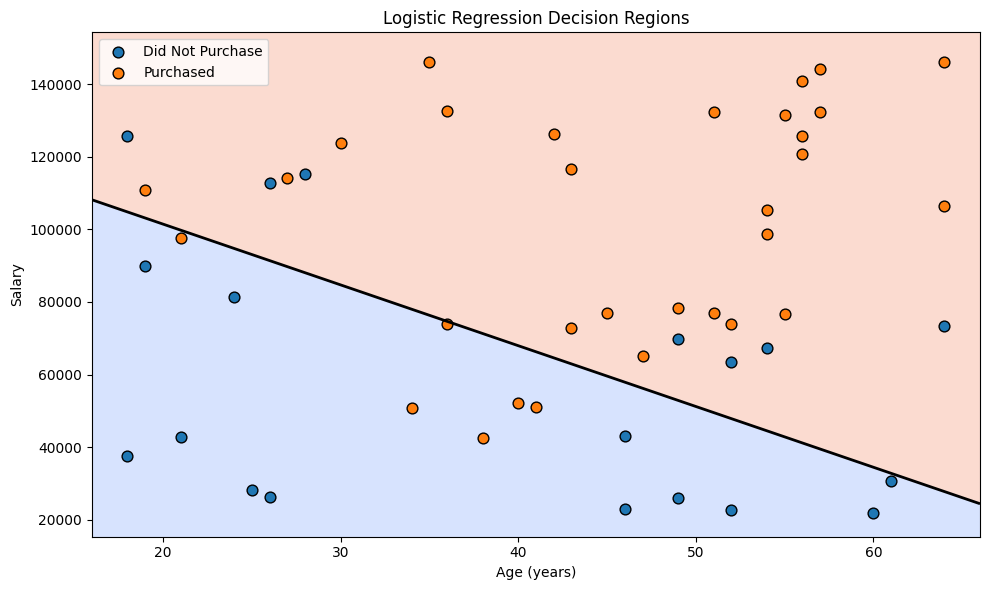

In [ ]:

# Step 7: Visualization of Decision Regions

# Create a grid of Age and Salary values
age_min, age_max = X["Age"].min() - 2, X["Age"].max() + 2
salary_min, salary_max = X["Salary"].min() - 5000, X["Salary"].max() + 5000

age_grid, salary_grid = np.meshgrid(
    np.linspace(age_min, age_max, 200),
    np.linspace(salary_min, salary_max, 200)
)

# Combine grid points and scale them
grid_points = np.column_stack([
    age_grid.ravel(),
    salary_grid.ravel()
])

grid_scaled = scaler.transform(grid_points)

# Predict purchase probabilities for each grid point
probabilities = model.predict_proba(grid_scaled)[:, 1]
probability_grid = probabilities.reshape(age_grid.shape)

# Plot the decision regions
plt.figure(figsize=(10, 6))

plt.contourf(
    age_grid,
    salary_grid,
    probability_grid,
    levels=[0, 0.5, 1],
    alpha=0.35,
    cmap="coolwarm"
)

# Draw the decision boundary at 50% probability
plt.contour(
    age_grid,
    salary_grid,
    probability_grid,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Plot the actual test data
for value, label in [(0, "Did Not Purchase"), (1, "Purchased")]:
    mask = y_test.to_numpy() == value

    plt.scatter(
        X_test.loc[mask, "Age"],
        X_test.loc[mask, "Salary"],
        label=label,
        edgecolors="black",
        s=60
    )

# Add labels and title
plt.xlabel("Age (years)")
plt.ylabel("Salary")
plt.title("Logistic Regression Decision Regions")
plt.legend()
plt.tight_layout()
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here